<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 5.6 - Geospatial Data (Bonus)</h2>
<p>Locations create relationships between records. The original Toronto map connects station coordinates with neighbourhood boundaries. The optional examples add shapes, projected measurements, spatial joins and a public-library dataset.</p>
<p>Central question: how do coordinates and geometry answer questions about place, distance and overlap?</p>
<p>After this notebook, you should identify coordinate order, check a coordinate reference system, build a layered map, join points to polygons, and interpret straight-line distances with suitable limits.</p>
<a id="lecture-structure"></a>
<h3>Lecture Structure</h3>
<ol><li><a href="#section1">Import Bike Share Data</a></li>
<li><a href="#section2">Map Toronto Locations</a></li></ol>
<p><a href="#lecture-summary">Lecture summary</a></p>
<h3>Optional extensions</h3>
<ol start="3"><li><a href="#section3">Points, lines and polygons</a></li>
<li><a href="#section4">Stations within neighbourhoods</a></li>
<li><a href="#section5">Distance and buffers</a></li>
<li><a href="#section6">Libraries and nearby bike stations</a></li></ol>
<p>Run Setup Notebook first. Follow the numbered section links from the slides. Run each section in order. The optional extensions follow the lecture summary.</p>
<h3>Sources and documentation</h3>
<p><a href="../slides/week5_lecture6.pptx">Lecture slides</a> | <a href="DATA_SOURCES.html">Dataset sources, fields and limitations</a> | <a href="https://geopandas.org/en/stable/docs.html">GeoPandas documentation</a></p>

<h2>Setup Notebook</h2><p>The course environment supplies pandas, Matplotlib, GeoPandas and Shapely. All maps use local files. No web basemap or network connection is required.</p>
<p>Data operations stay visible below. Repeated figure layouts live in <a href="utils.py">utils.py</a>.</p>

In [1]:
# Third-party libraries
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString, Polygon

# Local plotting defaults
import utils
from utils import configure_plots

%matplotlib inline
configure_plots()
pd.set_option('display.max_columns', 7)
pd.set_option('display.max_rows', 8)

<p>GeoPandas and its coordinate-system dependencies belong in the course environment. The notebook starts directly with imports rather than installing packages.</p>

<a id='section1'></a>
<h2>1. Import Bike Share Data</h2>
<p>Question: Which columns locate each bike-share station? Run Setup Notebook first, then load the coordinate table used by the map. Its lon and lat columns hold longitude and latitude.</p>

In [2]:
bikeshare_stations = pd.read_csv('stations.csv')

<p>Inspect a few station names and coordinates before drawing a map. The supplied snapshot contains 608 station records.</p>

In [3]:
bikeshare_stations[['Station Id', 'Station Name', 'lon', 'lat']].head()

,Station Id,Station Name,lon,lat
0,7000,Fort York Blvd / Capreol Ct,-79.395954,43.639832
1,7001,Lower Jarvis St / The Esplanade,-79.370698,43.647830
2,7002,St. George St / Bloor St W,-79.399429,43.667333
3,7003,Madison Ave / Bloor St W,-79.402761,43.667158
4,7004,University Ave / Elm St,-79.389099,43.656518


<p>Toronto longitudes are negative because the city lies west of the prime meridian. Swapping the coordinate columns places the points far from Toronto.</p>

<p>Takeaway: longitude locates a station east or west, and latitude locates a station north or south. A point uses the order <code>(longitude, latitude)</code>.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section2"></a>
<h2>2. Map Toronto Locations</h2>
<p>Question: How are coordinate tables combined with a neighbourhood map? The next cell loads the polygons, creates the point geometries and plots the bike stations, weather station and University of Toronto location.</p>

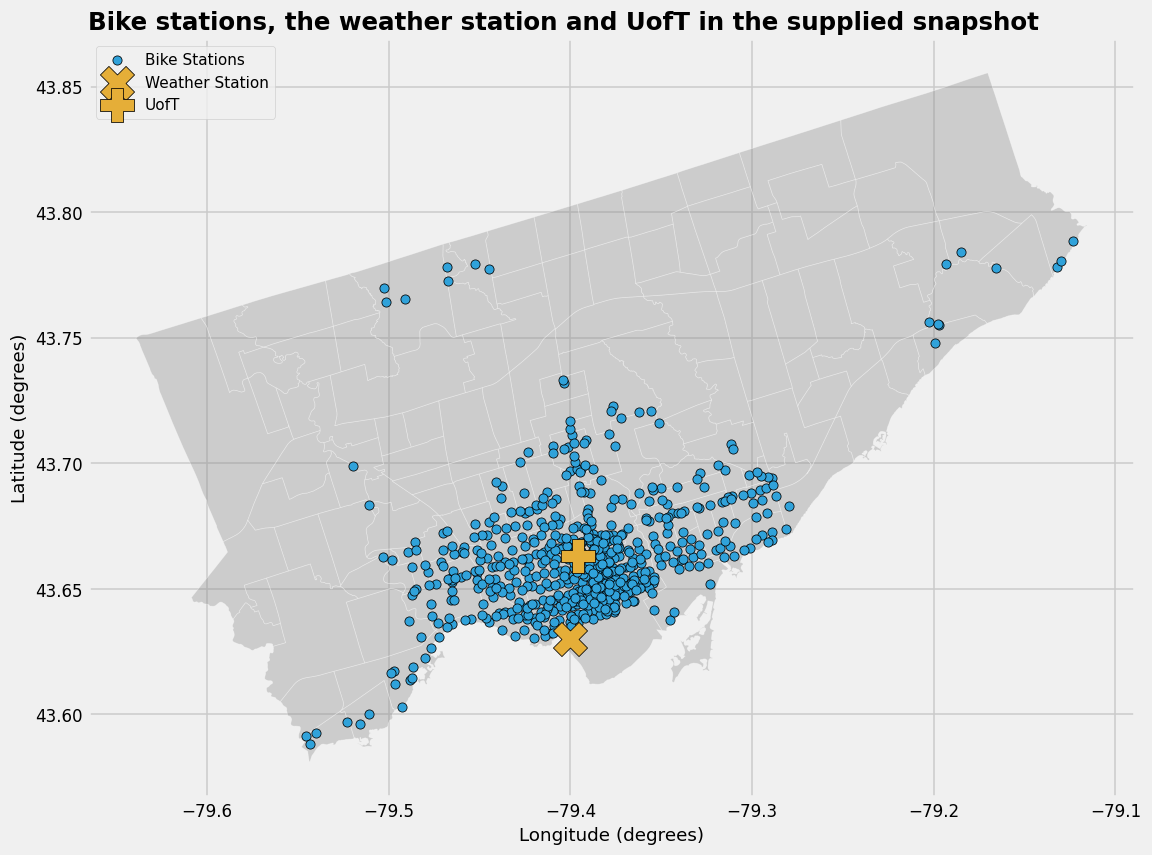

In [4]:
# Import the Toronto neighbourhoods shape file
regions = gpd.read_file('toronto_neighbourhoods.shp')

# Create a GeoDataFrame of bikeshare_stations
bikeshare_stations_gdf = gpd.GeoDataFrame(bikeshare_stations, 
                                          geometry=gpd.points_from_xy(bikeshare_stations.lon, 
                                                                      bikeshare_stations.lat), crs="EPSG:4326")

# Create a GeoDataFrame of the TORONTO CITY CENTRE weather station
weather_station_df = pd.DataFrame({'lat': [43.63], 
                                   'lon': [-79.4]})
weather_station_gdf = gpd.GeoDataFrame(weather_station_df, 
                                       geometry=gpd.points_from_xy(weather_station_df.lon, 
                                                                   weather_station_df.lat), crs="EPSG:4326")

# Create a GeoDataFrame for UofT location
uoft_df = pd.DataFrame({'lat': [43.6629], 'lon': [-79.3957]})
uoft_gdf = gpd.GeoDataFrame(uoft_df,
                            geometry=gpd.points_from_xy(uoft_df.lon,
                                                        uoft_df.lat), crs="EPSG:4326")
utils.plot_original_toronto_layers(regions, bikeshare_stations_gdf, weather_station_gdf, uoft_gdf)

<h3>Read the geometry and coordinate system</h3><p>GeoPandas adds a geometry column to the table. The existing polygons and the station points use WGS84 longitude and latitude, identified by <code>EPSG:4326</code>.</p>

In [5]:
print('Neighbourhood CRS:', regions.crs)
print('Station CRS:', bikeshare_stations_gdf.crs)
print('Geometry types:', regions.geom_type.unique(), bikeshare_stations_gdf.geom_type.unique())

Neighbourhood CRS: EPSG:4326
Station CRS: EPSG:4326
Geometry types: ['Polygon'] ['Point']


<p>The file supplies polygon boundaries, while the coordinate table supplies points. A shared CRS defines where both layers sit on Earth.</p>

<h3>Inspect the local map</h3><p>A downtown view separates nearby stations. The same observations appear at a different map extent.</p>

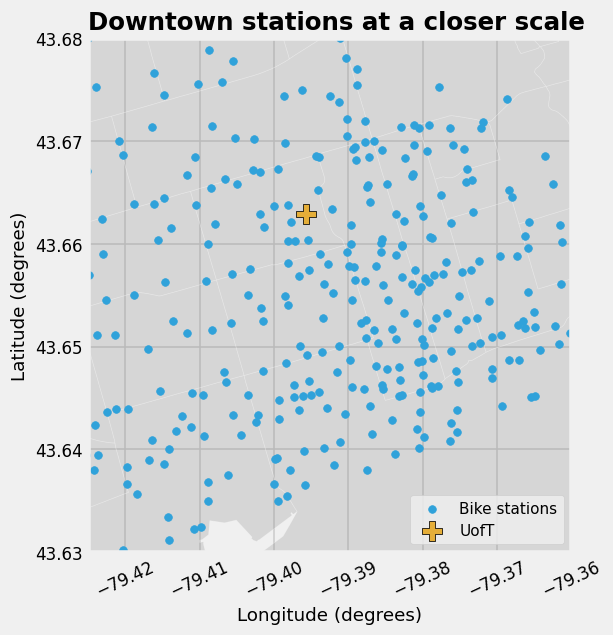

In [6]:
utils.plot_downtown(regions, bikeshare_stations_gdf, uoft_gdf)

<p>The closer view resolves stations hidden by overlapping symbols at the city scale. The map shows locations rather than available bicycles or docking capacity.</p>

<p>Takeaway: matching coordinate systems place several layers on one map. Map extent and symbol size determine which local patterns are visible.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="lecture-summary"></a><h2>Lecture summary</h2>
<ul><li>A point uses x then y, which means longitude then latitude for these input files.</li><li>A GeoDataFrame combines attributes with geometry.</li><li>Check CRS information before overlaying layers.</li><li>Choose map extent and symbols to reveal the observations.</li><li>Distinguish locations from evidence about service availability.</li></ul>

<a id='section3'></a>
<h2>3. Points, lines and polygons</h2>
<p>Optional extension.</p>
<p>Question: which geometry represents a monitoring site, a route and a service zone?</p>

<h3>Construct three geometries</h3>
<p>Use invented local metre coordinates to isolate the three shapes. The point marks a monitoring site, the line represents a route, and the polygon represents a service zone. These shapes do not represent real Toronto features.</p>

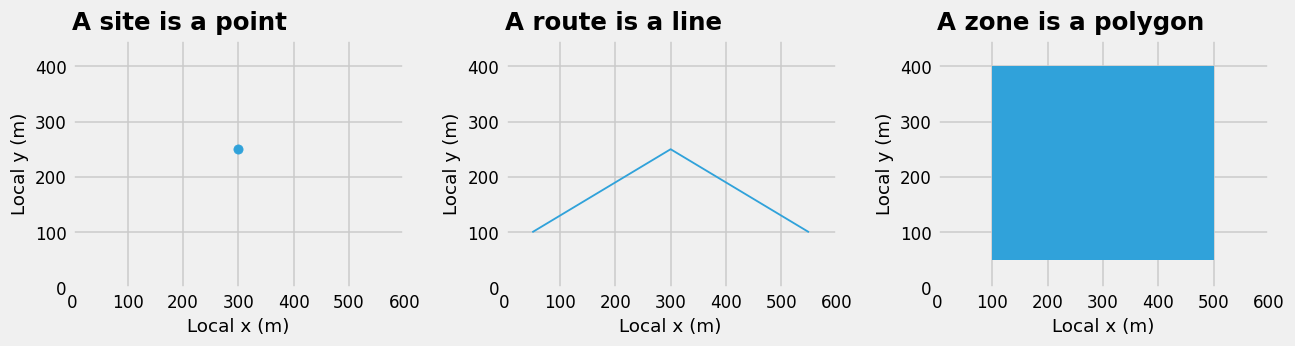

In [7]:
site = Point(300, 250)
route = LineString([(50, 100), (300, 250), (550, 100)])
zone = Polygon([(100, 50), (500, 50), (500, 400), (100, 400)])
utils.plot_geometry_types(site, route, zone)

<p>The point has a location, the line has length, and the polygon encloses area. All three views share the same local coordinate scale.</p>

<h3>Measure geometric relationships</h3>
<p>Geometry methods calculate measurements and relationships. A point on the boundary differs from a point strictly inside the polygon.</p>

In [8]:
boundary_site = Point(100, 250)
print('Route length (m):', round(route.length, 1))
print('Zone area (m²):', zone.area)
print('Site strictly inside zone:', site.within(zone))
print('Boundary point strictly inside zone:', boundary_site.within(zone))
print('Boundary point intersects zone:', boundary_site.intersects(zone))

Route length (m): 583.1
Zone area (m²): 140000.0
Site strictly inside zone: True
Boundary point strictly inside zone: False
Boundary point intersects zone: True


<p><code>within</code> excludes the boundary in this point–polygon example. <code>intersects</code> includes contact. The chosen relationship affects which records a spatial join returns.</p>

<p>Takeaway: choose the geometry and spatial relationship to match the question.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section4'></a>
<h2>4. Stations within neighbourhoods</h2>
<p>Optional extension.</p>
<p>Question: how many station locations fall within each supplied neighbourhood boundary?</p>

<h3>Assign stations to neighbourhoods</h3>
<p>Keep the neighbourhood name and geometry. A spatial join attaches a polygon name to each station using the point-in-polygon relationship. A left join retains unmatched stations for inspection.</p>

In [9]:
neighbourhoods = regions[['FIELD_7', 'geometry']].rename(columns={'FIELD_7': 'neighbourhood'})
stations = bikeshare_stations_gdf[['Station Id', 'Station Name', 'geometry']].copy()
station_areas = gpd.sjoin(stations, neighbourhoods, how='left', predicate='within')
print('Station rows:', len(stations))
print('Joined rows:', len(station_areas))
print('Unmatched stations:', station_areas['neighbourhood'].isna().sum())
station_areas[['Station Name', 'neighbourhood']].head()

Station rows: 608
Joined rows: 608
Unmatched stations: 0


,Station Name,neighbourhood
0,Fort York Blvd / Capreol Ct,Waterfront Communities-The Island (77)
1,Lower Jarvis St / The Esplanade,Waterfront Communities-The Island (77)
2,St. George St / Bloor St W,University (79)
3,Madison Ave / Bloor St W,Annex (95)
4,University Ave / Elm St,Kensington-Chinatown (78)


<p>The polygon name comes from location rather than a shared text key. An unmatched point requires checking the coordinates, boundary coverage and boundary rule.</p>

<h3>Calculate counts and area density</h3>
<p>Count the matched stations and join the counts back to all polygons. Zero means no matched station in this supplied snapshot. Project the polygons to UTM zone 17N before measuring area in square kilometres.</p>

In [10]:
station_counts = station_areas.groupby('neighbourhood').size().rename('station_count')
area_counts = neighbourhoods.join(station_counts, on='neighbourhood')
area_counts['station_count'] = area_counts['station_count'].fillna(0).astype(int)
area_counts = area_counts.to_crs('EPSG:32617')
area_counts['area_km2'] = area_counts.area / 1_000_000
area_counts['stations_per_km2'] = area_counts['station_count'] / area_counts['area_km2']
area_counts[['neighbourhood', 'station_count', 'area_km2', 'stations_per_km2']].head().round(2)

,neighbourhood,station_count,area_km2,stations_per_km2
0,Wychwood (94),9,1.68,5.35
1,Yonge-Eglinton (100),9,1.65,5.45
2,Yonge-St.Clair (97),1,1.16,0.86
3,York University Heights (27),3,13.25,0.23
4,Yorkdale-Glen Park (31),0,6.04,0.00


<p>Counts answer how many locations fall inside a boundary. Area density answers how many locations lie in each square kilometre, on average. Neither measure includes population or demand.</p>

<h3>Compare map denominators</h3>
<p>Compare two choropleths, where polygon colour represents a numerical value. Use separate legends because count and density have different units.</p>

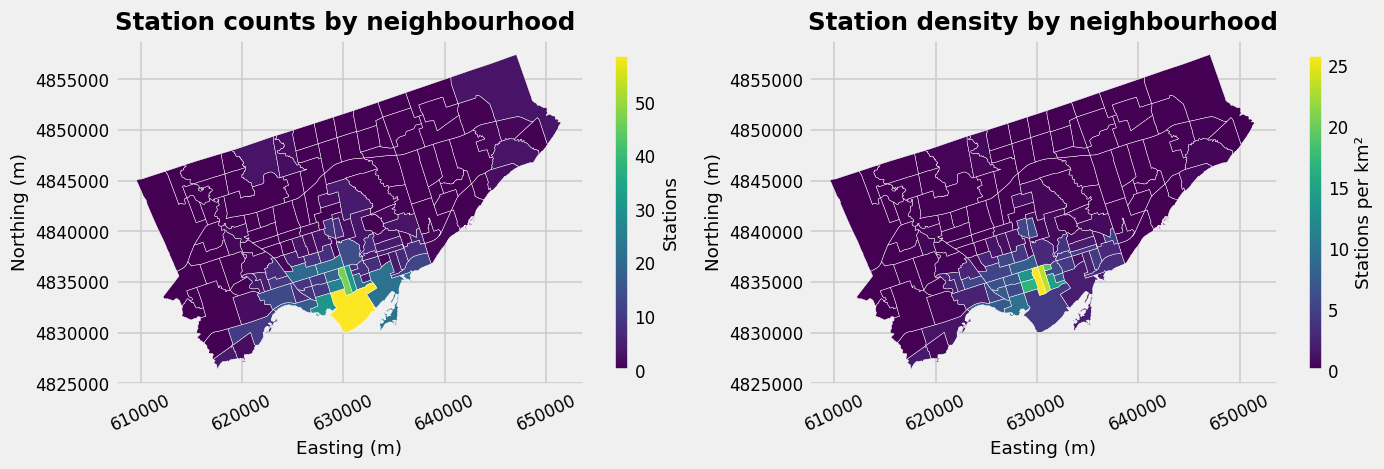

In [11]:
utils.plot_count_and_density(area_counts)

<p>A neighbourhood with many stations does not necessarily have the highest density. The older 140-neighbourhood boundaries remain the unit of comparison throughout this example.</p>

<p>Takeaway: spatial joins turn locations into groups. The choice of count, area density or another denominator changes the map question.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section5'></a>
<h2>5. Distance and buffers</h2>
<p>Optional extension.</p>
<p>Question: which stations lie within a straight-line distance of 500 metres from the supplied UofT point?</p>

<h3>Transform coordinates before measuring</h3>
<p><code>set_crs</code> declares the meaning of existing coordinates. <code>to_crs</code> transforms those coordinates. Use a local projected CRS for this distance calculation. UTM zone 17N measures this Toronto region in metres.</p>

In [12]:
stations_utm = bikeshare_stations_gdf.to_crs('EPSG:32617')
regions_utm = regions.to_crs('EPSG:32617')
uoft_utm = uoft_gdf.to_crs('EPSG:32617')
print('UofT longitude and latitude:', uoft_gdf.geometry.iloc[0])
print('UofT easting and northing:', uoft_utm.geometry.iloc[0])
stations_utm['distance_m'] = stations_utm.distance(uoft_utm.geometry.iloc[0])
stations_utm[['Station Name', 'distance_m']].sort_values('distance_m').head().round(1)

UofT longitude and latitude: POINT (-79.3957 43.6629)
UofT easting and northing: POINT (629350.1504754095 4835683.44988985)


,Station Name,distance_m
66,Willcocks St / St. George St - SMART,187.4
179,St. George St / Hoskin Ave,212.3
328,Gailbraith Rd / King’s College Cr. (U of T),280.8
416,Queen's Park Cres W / Hoskin Ave,291.7
8,Wellesley St / Queen's Park Cres,293.1


<p>The location stays fixed while its numerical coordinates change. Distances are straight-line gaps from the chosen campus point, rather than from every campus entrance.</p>

<h3>Select stations within a buffer</h3>
<p>A buffer surrounds a point by a chosen radius. Use a distance comparison to select stations at or within 500 metres, then display the same radius on a map.</p>

Stations within 500 m: 11


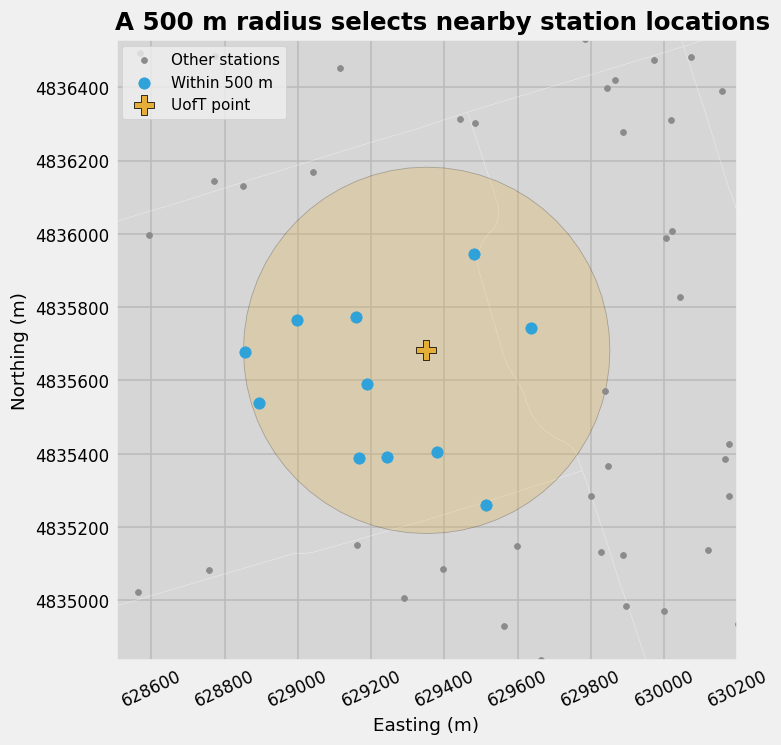

In [13]:
buffer_500m = uoft_utm.buffer(500)
nearby = stations_utm.loc[stations_utm['distance_m'].le(500)]
print('Stations within 500 m:', len(nearby))
utils.plot_nearby_stations(regions_utm, stations_utm, nearby, uoft_utm, buffer_500m)

<p>The circle is a straight-line buffer. Roads, building entrances, fences and other barriers affect travel distance. The highlighted stations therefore do not define a five-minute walking catchment.</p>

<h3>Vary the distance threshold</h3>
<p>Change the radius while holding the station snapshot fixed. The selected count should never decrease as the radius grows.</p>

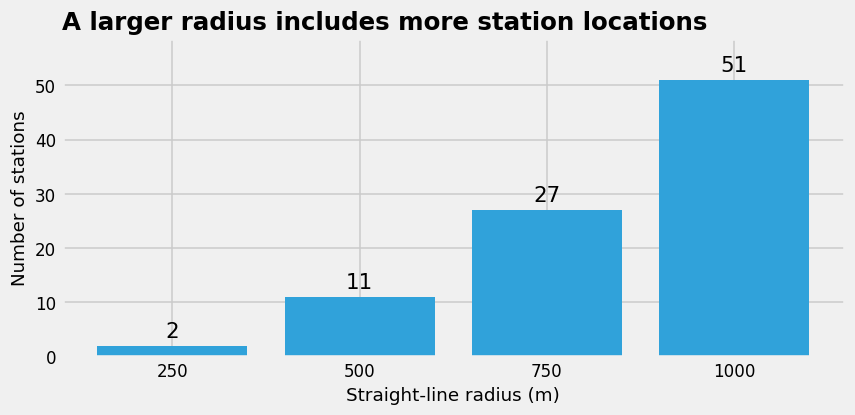

In [14]:
radii = [250, 500, 750, 1000]
counts = [stations_utm['distance_m'].le(radius).sum() for radius in radii]
utils.plot_radius_comparison(radii, counts)

<p>The chosen radius changes the answer. The counts describe station locations and do not measure bike availability, service quality or demand.</p>

<p>Takeaway: project coordinates before measuring metres, and keep straight-line proximity distinct from travel accessibility.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section6'></a>
<h2>6. Libraries and nearby bike stations</h2>
<p>Optional extension.</p>
<p>Question: which recorded bike station is closest to each library branch?</p>

<h3>Load the library locations</h3>
<p>The added local table contains 100 physical Toronto Public Library branches from the 2023 open-data release. The source also lists other services, excluded from this extract. This comparison combines a dated library extract with the undated course station snapshot, so the result demonstrates a method rather than current service coverage.</p>

In [15]:
library_table = pd.read_csv('toronto_library_branches_2023.csv')
libraries = gpd.GeoDataFrame(library_table,
    geometry=gpd.points_from_xy(library_table['Long'], library_table['Lat']), crs='EPSG:4326')
libraries_utm = libraries.to_crs('EPSG:32617')
nearest = gpd.sjoin_nearest(libraries_utm,
    stations_utm[['Station Id', 'Station Name', 'geometry']],
    how='left', distance_col='nearest_station_m')
print('Physical library branches:', len(libraries))
print('Nearest matches, including exact ties:', len(nearest))
nearest[['BranchName', 'Station Name', 'nearest_station_m']].head().round(1)

Physical library branches: 100
Nearest matches, including exact ties: 100


,BranchName,Station Name,nearest_station_m
0,Albion,Weston Lions Park,6916.2
1,Albert Campbell,Victoria Park Subway Station - SMART,2224.6
2,Alderwood,Long Branch GO Station,1159.1
3,Agincourt,Livingston Rd (Highland Creek Trail),7985.1
4,Armour Heights,Teddington Park Ave,1604.1


<p>The join measures proximity without requiring matching branch and station names. Exact distance ties would return more than one row for a branch.</p>

<h3>Map nearest-station distances</h3>
<p>Show library locations over the same station layer. Colour each branch by the distance to its nearest station. Triangle symbols distinguish libraries from station points.</p>

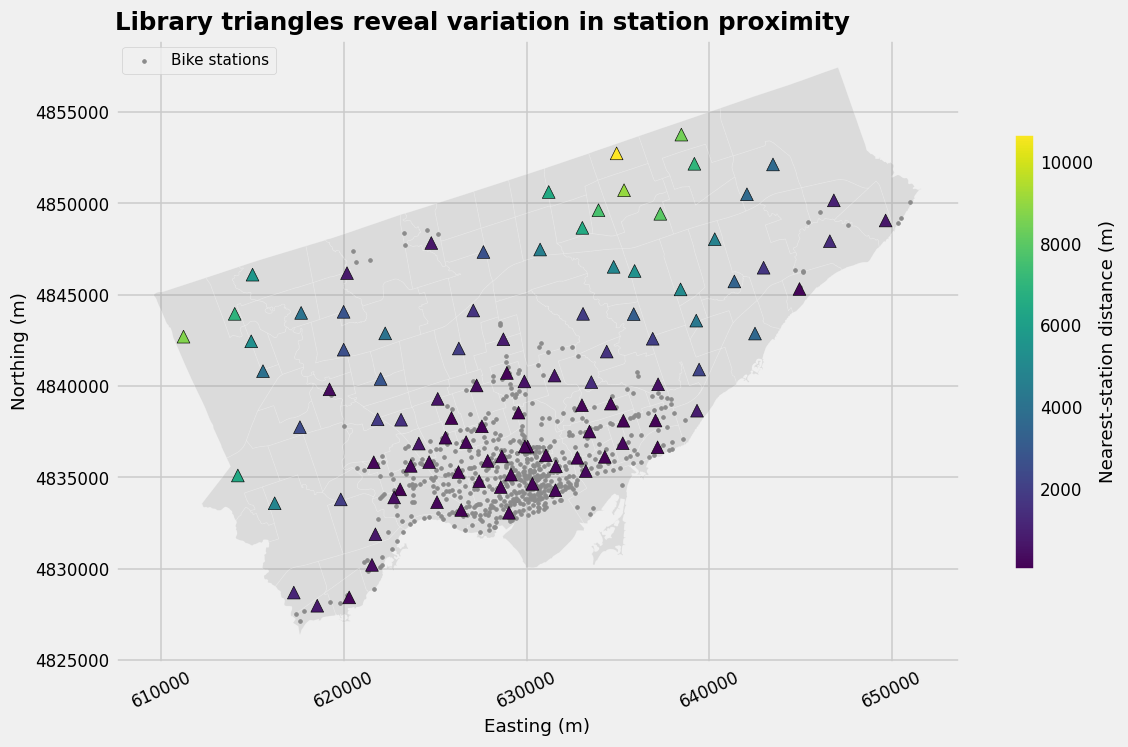

In [16]:
utils.plot_library_proximity(regions_utm, stations_utm, nearest)

<p>Branches beyond dense station clusters have longer nearest-station distances in these files. Different snapshot dates, entrances and street routes limit an accessibility interpretation.</p>

<h3>Inspect the longest connections</h3>
<p>Inspect the five branches with the largest straight-line distances. Draw a line to the selected station to expose what the nearest join measured. Resolve exact ties by station ID for this display only.</p>

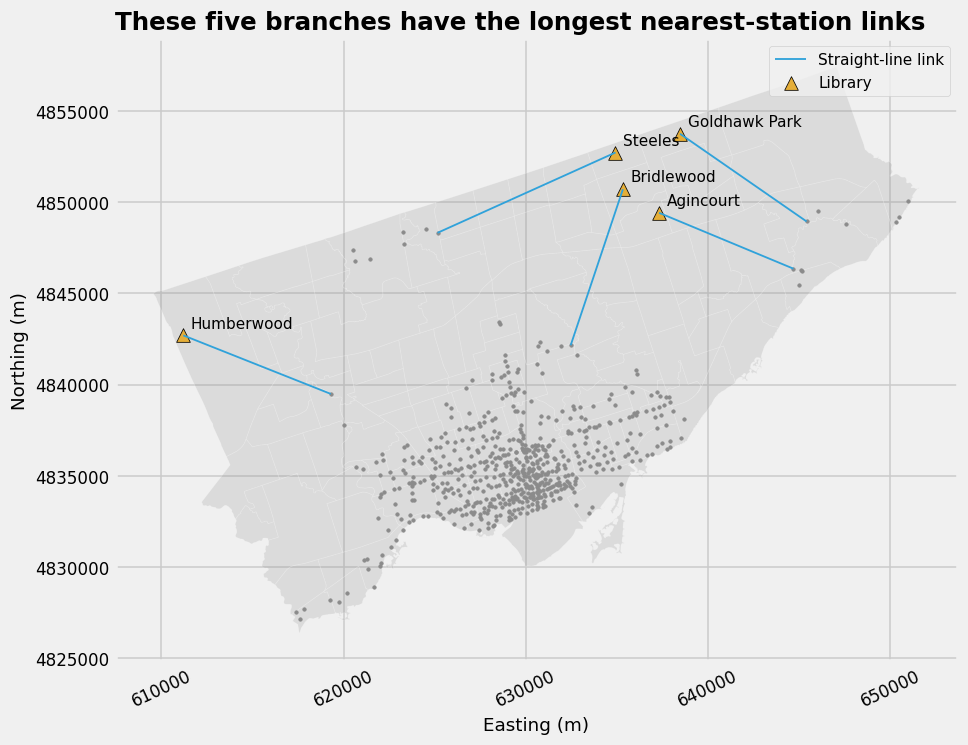

In [17]:
one_match = nearest.sort_values(['BranchCode', 'nearest_station_m', 'Station Id']).drop_duplicates('BranchCode')
farthest = one_match.nlargest(5, 'nearest_station_m')
station_points = stations_utm.set_index('Station Id').geometry
connections = gpd.GeoSeries([
    LineString([row.geometry, station_points.loc[row['Station Id']]])
    for _, row in farthest.iterrows()], crs='EPSG:32617')
utils.plot_library_connections(regions_utm, stations_utm, farthest, connections)

<p>The connectors show Euclidean distances, rather than routes. A service-planning study would also need matched dates, opening hours, entrances, network distances and relevant demand.</p>

<p>Takeaway: nearest joins connect separate location datasets. Interpret the resulting distances using the data dates and the measurement definition.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>